In [1]:
import numpy as np
from scipy import special
from scipy.linalg import solve, kron
from scipy.linalg import solve_continuous_lyapunov
from scipy.linalg import lstsq
from scipy.integrate import cumtrapz   #from scipy.integrate import cumulative_trapezoids
from scipy.integrate import quad

import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.patches import FancyArrowPatch
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import seaborn as sns

from typing import Callable, Tuple, Optional, Union
from tqdm import tqdm
import mpmath   #for high precision calculations

from stabilizing import *

sns.set(style="white")
sns.set_context("notebook")

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{lmodern}"
})


from matplotlib.colors import LinearSegmentedColormap
ccn_color = "#007f9d"
ccn_cmap = LinearSegmentedColormap.from_list("custom_007f9d", ["#ffffff", ccn_color])

In [2]:
def power_iteration(A, num_iterations: int):
    b_k = np.random.rand(A.shape[1])

    for _ in range(num_iterations):
        # calculate the matrix-by-vector product Ab
        b_k1 = np.dot(A, b_k)

        # calculate the norm
        b_k1_norm = np.linalg.norm(b_k1)

        # re normalize the vector
        b_k = b_k1 / b_k1_norm

    return b_k

def scalar_projections(traj: np.ndarray, v_u: np.ndarray, v_s: np.ndarray):
    """
    Project 2D trajectory onto unstable and stable directions.

    Parameters:
        traj: shape (2, T)
        v_u, v_s: eigenvectors (2,)

    Returns:
        proj_u, proj_s: scalar projections (T,)
    """
    v_u = v_u / np.linalg.norm(v_u)
    v_s = v_s / np.linalg.norm(v_s)
    proj_u = v_u @ traj  # shape (T,)
    proj_s = v_s @ traj  # shape (T,)
    return proj_u, proj_s

def directional_projection_onto_vu_along_vs(traj: np.ndarray, v_u: np.ndarray, v_s: np.ndarray) -> np.ndarray:
    """
    traj: shape (T, 2)
    Returns: projected_traj shape (T, 2)
    """
    traj = traj.T  # now (2, T)
    v_u = v_u / np.linalg.norm(v_u)
    v_s = v_s / np.linalg.norm(v_s)
    v_u_perp = np.array([-v_u[1], v_u[0]])

    numerators = v_u_perp @ traj          # (T,)
    denominator = v_u_perp @ v_s          # scalar

    alphas = -numerators / denominator    # (T,)
    projected_traj = traj + v_s[:, None] * alphas[None, :]  # (2, T)
    return projected_traj.T  # back to (T, 2)

def project_onto_eigenvector(u: np.ndarray, V: np.ndarray) -> np.ndarray:
    """
    Projects the vector u onto the eigenvector v_1 of a matrix A = V Λ V^{-1},
    where V is the matrix of right eigenvectors.

    Parameters:
    - u: vector to project (n,)
    - V: matrix of eigenvectors (n, n), columns are v_1, ..., v_n

    Returns:
    - projection: projection of u onto v_1
    """
    V_inv = np.linalg.inv(V)
    v1 = V[:, 0]           # first (unstable) right eigenvector
    w1 = V_inv[0, :]       # first left eigenvector (row of V^{-1})

    alpha = np.dot(w1, u)  # w1^T u
    projection = alpha * v1
    return projection

def compute_empirical_committor_projection(
    trajs: np.ndarray,
    A: np.ndarray,
    Q: np.ndarray,
    Lambda: np.ndarray,
    a: float,
    num_bins: int = 10,
    bin_edges: np.ndarray = None
) -> tuple:
    """
    Compute empirical committor as the probability of hitting proj < -a before proj > a.

    Parameters:
        trajs: Trajectories, shape (B, T, N)
        A, Q, Lambda: eigendecomposition of A = Q @ Lambda @ Q^{-1}
        a: Threshold for defining boundary in projection space
        num_bins: Number of bins to average committor estimates over initial projection values
        bin_edges: Optional bin edges

    Returns:
        bin_centers: Projection values of initial conditions (length = num_bins)
        committor_vals: Empirical committor values (length = num_bins)
        n_uncommitted: Number of trajectories that did not hit either boundary
    """
    B, T, N = trajs.shape
    eigvals = np.diag(Lambda)
    unstable_idx = np.argmax(np.real(eigvals))
    v_u = np.real(Q[:, unstable_idx])
    v_u /= np.linalg.norm(v_u)
    v_s = np.real(Q[:, unstable_idx+1])
    v_s /= np.linalg.norm(v_s)

    # Project initial conditions along unstable direction
    x0s = trajs[:, 0, :]               # shape (B, N)
    proj0 = x0s @ v_u                  # shape (B,)
    
    hit_minus_before_plus = np.zeros(B, dtype=bool)
    is_committed = np.zeros(B, dtype=bool)
    n_uncommitted = 0

    for i in range(B):
        #traj_proj = directional_projection_onto_vu_along_vs(trajs[i, :, :], v_u, v_s)
        traj_proj_scalar = trajs[i, :, :] @ v_u
        #traj_proj = trajs[i, :, :] @ v_u  # shape (T,)
        for p in traj_proj_scalar:
            if p < -a:
                hit_minus_before_plus[i] = True
                is_committed[i] = True
                break
            elif p > a:
                hit_minus_before_plus[i] = False
                is_committed[i] = True
                break
        if not is_committed[i]:
            n_uncommitted += 1

    # Bin initial projection values
    if bin_edges is None:
        bin_edges = np.linspace(proj0.min(), proj0.max(), num_bins + 1)
    else:
        num_bins = len(bin_edges) - 1

    bin_indices = np.digitize(proj0, bin_edges) - 1
    committor_vals = np.zeros(num_bins)
    counts = np.zeros(num_bins)

    for i in range(B):
        b = bin_indices[i]
        if 0 <= b < num_bins and is_committed[i]:
            committor_vals[b] += hit_minus_before_plus[i]
            counts[b] += 1

    with np.errstate(invalid='ignore'):
        committor_vals = np.where(counts > 0, committor_vals / counts, np.nan)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    return bin_centers, committor_vals, n_uncommitted

def make_committor_and_control_from_projection(lambda_u: float, D: float, a: float):
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)
    Z = special.erf(a * sqrt_r) - special.erf(-a * sqrt_r)

    def committor(p: float) -> float:
        return (special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)) / Z

    def control(p: float) -> float:
        q_val = committor(p)
        if q_val < 1e-8:
            return 0.0  # Avoid division by zero
        dq_dp = (2 / np.sqrt(np.pi)) * sqrt_r * np.exp(-r * p**2) / Z
        return D * dq_dp / q_val

    return committor, control


def sample_initial_conditions_between_sets(Q: np.ndarray, Lambda: np.ndarray, a: float, b: float, nsims: int, seed: int = 0):
    """
    Sample points x0 such that ⟨v_u, x0⟩ ∈ (−a, +a) and ⟨v_s, x0⟩ ∈ (−b, +b),
    where v_u and v_s are the unstable and stable eigenvectors of A.

    Returns:
        x0s: list of sampled points in R^2.
    """
    eigvals = Lambda
    unstable_idx = np.argmax(np.real(eigvals))
    stable_idx = np.argmin(np.real(eigvals))

    v_u = np.real(Q[:, unstable_idx])
    v_s = np.real(Q[:, stable_idx])
    v_u /= np.linalg.norm(v_u)
    v_s /= np.linalg.norm(v_s)
    v_s_ortho = np.array([-v_s[1], v_s[0]])  # orthogonal to v_s

    rng = np.random.default_rng(seed)
    x0s = []

    for _ in range(nsims):
        proj_u = rng.uniform(-a, a)
        proj_s = rng.uniform(-b, b)
        x0 = proj_u * v_s_ortho + proj_s * v_s
        x0s.append(x0)

    return np.array(x0s)    


In [3]:
def draw_arrowhead_only(ax, tail, direction, color='blue', head_length=0.3):
    """
    Draw only an arrowhead pointing from `tail` in `direction`.
    """
    direction = direction / np.linalg.norm(direction)
    head = tail + head_length * direction

    # The visible "shaft" is nearly zero
    arrow = FancyArrowPatch(
        posA=head, posB=tail,  # Reversed order, so head is at `head`
        arrowstyle='-|>',  # or '->'
        mutation_scale=10,
        color=color,
        linewidth=0,  # no line
        shrinkA=0,
        shrinkB=0
    )
    ax.add_patch(arrow)

def plot_eigendirections(ax, Q, Lambda, a, color_scheme=('red', 'green'), label=True):
    for i in range(2):
        vec = Q[:, i]
        vec = vec / np.linalg.norm(vec)
        lam = Lambda[i, i]
        color = color_scheme[0] if lam > 0 else color_scheme[1]
        line_pts = np.linspace(-10, 10, 100)
        ax.plot(line_pts * vec[0], line_pts * vec[1], color=color, linestyle='-', label=f"$\\lambda = {lam:.2f}$" if label else None, alpha=0.5)

        # for s in [-1, +1]:
        #     tail = s * vec
        #     direction = np.sign(s) * np.sign(lam) * vec
        #     direction /= np.linalg.norm(direction)
        #     head = tail + 0.6 * direction
        #     ax.annotate('', xy=head, xytext=tail, arrowprops=dict(arrowstyle='fancy', color=color, lw=1.5), alpha=0.5)

        for s in [-1, +1]:
            tail = s * vec
            direction = -np.sign(s) * np.sign(lam) * vec
            direction /= np.linalg.norm(direction)
            head = tail + 0.001 * direction  # Tiny shaft length

            arrow = FancyArrowPatch(
                posA=head, posB=tail,  # reverse so arrow points from tail to head
                arrowstyle='-|>',
                mutation_scale=25,    # arrowhead size
                color=color,
                linewidth=0,          # hide shaft line
                shrinkA=0,
                shrinkB=0,
                alpha=0.8
            )
            ax.add_patch(arrow)

def plot_set_boundaries(ax, a: float, Q: np.ndarray, Lambda: np.ndarray,
                        color='black', linestyle='--', label=True, a_multiplier_lim=4):
    """
    Plot the two boundary lines {x: <v_u, x> = ±a} in the 2D phase plane.

    Parameters:
        ax: matplotlib axis to draw on.
        a: scalar threshold (distance along unstable direction).
        Q, Lambda: eigendecomposition of A = Q Λ Q^{-1}.
    """
    eigvals = np.diag(Lambda)
    unstable_idx = np.argmax(np.real(eigvals))
    v_u = np.real(Q[:, 0])
    v_u /= np.linalg.norm(v_u)

    # Perpendicular direction
    v_s = np.real(Q[:, 1])
    v_s /= np.linalg.norm(v_u)
    v_s_ortho = np.array([-v_s[1], v_s[0]])  # 90-degree rotation

    # Generate points along each boundary line
    line_range = np.linspace(-a_multiplier_lim*a, a_multiplier_lim*a, 20)

    for sign in [+1, -1]:
        center = sign * a * v_s_ortho  # shift from origin
        line_pts = center[:, None] + v_s[:, None] * line_range[None, :] 
        ax.plot(line_pts[0], line_pts[1],
                color=color,
                linestyle=linestyle,
                label=f"$\\langle v_s, x \\rangle = {sign}a$" if label else None)

    if label:
        ax.legend()

In [4]:
def plot_control_effect(
    A: np.ndarray,
    control_function,  # Takes distance to A as input
    Q_mat: np.ndarray,
    a: float,
    xlim: tuple = (-10, 10),
    ylim: tuple = (-10, 10),
    grid_density: int = 20,
    dt: float = 0.05,
    magnitude_threshold: float = 1e-3
):
    assert A.shape == (2, 2), "This visualization is for 2D systems only."

    v_u = Q_mat[:, 0]
    v_u = v_u / np.linalg.norm(v_u)
    v_s = Q_mat[:, 1]
    v_s = v_s / np.linalg.norm(v_s)
    v_s_ortho = np.array([-v_s[1], v_s[0]])  # orthogonal to v_s

    x_vals = np.linspace(*xlim, grid_density)
    y_vals = np.linspace(*ylim, grid_density)
    X, Y = np.meshgrid(x_vals, y_vals)

    U_dir = np.zeros_like(X)
    V_dir = np.zeros_like(Y)
    Magnitude = np.zeros_like(X)

    for i in range(grid_density):
        for j in range(grid_density):
            x = np.array([X[i, j], Y[i, j]])
            x = A @ x

            proj_u = stable_direction_projection(x, v_u, v_s)

            if proj_u > -a:
                dist_to_A = proj_u
                u_scalar = control_function(dist_to_A)
                dx_ctrl = u_scalar * v_u
                dx_ctrl = u_scalar * v_s_ortho
            else:
                dx_ctrl = np.zeros(2)

            norm = np.linalg.norm(dx_ctrl)
            #dx_ctrl = np.log(dx_ctrl)
            #norm = np.log(norm)

            if norm > magnitude_threshold:
                dx_unit = dx_ctrl / norm
                U_dir[i, j] = dx_unit[0]
                V_dir[i, j] = dx_unit[1]
                Magnitude[i, j] = norm
            else:
                U_dir[i, j] = np.nan  # Will skip plotting
                V_dir[i, j] = np.nan
                Magnitude[i, j] = np.nan

    fig, ax = plt.subplots(1, 1, figsize=(12, 5), sharex=True, sharey=True)

    # Quiver with magnitude as color
    mask = ~np.isnan(Magnitude)
    Q = ax.quiver(
        X[mask], Y[mask],
        U_dir[mask], V_dir[mask],
        Magnitude[mask],
        cmap='viridis', scale=25, clim=(np.nanmin(Magnitude), np.nanmax(Magnitude))
    )
    cbar = fig.colorbar(Q, ax=ax, label='Control Magnitude')

    ax.set_title("Committor control (colored by strength)")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal')

    ax.quiver(0, 0, v_u[0], v_u[1], angles='xy', scale_units='xy',
              scale=1, color='red', label='Unstable Direction')

    plot_eigendirections(ax, Q_mat, np.diag(np.linalg.eigvals(A)), label=False)
    ax.legend(loc='lower center', fontsize=10, bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)

    plot_set_boundaries(ax, a, Q_mat, Lambda)

    plt.tight_layout()
    plt.show()


def plot_control_effect_modal(
    A: np.ndarray,
    control_function,  # Takes distance to A as input
    Q_mat: np.ndarray,
    a: float,
    xlim: tuple = (-10, 10),
    ylim: tuple = (-10, 10),
    grid_density: tuple = 7,
    dt: float = 0.05,
    magnitude_threshold: float = 1e-5,
    cmap = ccn_cmap
):
    assert A.shape == (2, 2), "This visualization is for 2D systems only."

    Lambda = np.diag(np.linalg.eigvals(A))
    v_u = Q_mat[:, 0]  # unstable
    v_u /= np.linalg.norm(v_u)
    v_s = Q_mat[:, 1]  # stable
    v_s /= np.linalg.norm(v_s)
    v_s_ortho = -np.array([-v_s[1], v_s[0]])  # orthogonal to v_s

    # Grid in modal coordinates (coordinates along v_u and v_s)
    x_vals = np.linspace(*(-a,a), grid_density)
    y_vals = np.linspace(*ylim, grid_density)
    X_modal, Y_modal = np.meshgrid(x_vals, y_vals)

    U_dir = np.zeros_like(X_modal)
    V_dir = np.zeros_like(Y_modal)
    Magnitude = np.zeros_like(X_modal)

    for i in range(grid_density):
        for j in range(grid_density):
            modal_coords = np.array([X_modal[i, j], Y_modal[i, j]])  # (u, s)
            x = Q_mat @ modal_coords  # map to original space

            proj_u = modal_coords[0]  # already along v_u in modal space
            # project onto stable direction
            proj_u = stable_direction_projection(x, v_u, v_s) 

            if proj_u > -a:
                dist_to_A = proj_u
                u_scalar = control_function(dist_to_A)
                dx_ctrl = u_scalar * v_u
                dx_ctrl = u_scalar * v_s_ortho

            else:
                dx_ctrl = np.zeros(2)

            norm = np.linalg.norm(dx_ctrl)

            if norm > magnitude_threshold:
                dx_unit = dx_ctrl / norm
                U_dir[i, j] = dx_unit[0]
                V_dir[i, j] = dx_unit[1]
                Magnitude[i, j] = norm
            else:
                U_dir[i, j] = np.nan
                V_dir[i, j] = np.nan
                Magnitude[i, j] = np.nan

    fig, ax = plt.subplots(figsize=(8, 6))

    # Compute transformed X, Y from modal grid
    X_flat, Y_flat = X_modal.flatten(), Y_modal.flatten()
    XY_orig = Q_mat @ np.vstack([X_flat, Y_flat])  # shape (2, N)
    v_s_mat = np.array([v_s_ortho, v_s]).T  # shape (2, 2)
    XY_orig = v_s_mat @ np.vstack([X_flat, Y_flat])
    X_orig = XY_orig[0, :].reshape(X_modal.shape)
    Y_orig = XY_orig[1, :].reshape(Y_modal.shape)

    mask = ~np.isnan(Magnitude)

    Q = ax.quiver(
        X_orig[mask], Y_orig[mask],
        U_dir[mask], V_dir[mask],
        Magnitude[mask],
        cmap=cmap, scale=15, clim=(np.nanmin(0), np.nanmax(1))
    )

    cbar = fig.colorbar(Q, ax=ax)
    cbar.ax.tick_params(labelsize=15)
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(['0', '1'])
    cbar.set_label('Control Magnitude', fontsize=15)

    #ax.set_title("Committor Control", fontsize=15)
    ax.set_xlabel("$x_1$", fontsize=15)
    ax.set_ylabel("$x_2$", fontsize=15)
    ax.set_aspect('equal')
    ax.set_xlim(np.min(X_orig), np.max(X_orig))
    ax.set_ylim(np.min(Y_orig), np.max(Y_orig))

    #ax.quiver(0, 0, v_u[0], v_u[1], angles='xy', scale_units='xy',
    #          scale=1, color='red', label='Unstable Direction')

    plot_eigendirections(ax, Q_mat, Lambda, a=a, label=False, color_scheme=('firebrick', 'darkgreen'))
    plot_set_boundaries(ax, a, v_s_mat, Lambda)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    ax.set_xticks([-a, 0, a], [r'$-a$', r'$0$', r'$a$'], fontsize=15)
    ax.set_yticks([-a, 0, a], [r'$-a$', r'$0$', r'$a$'], fontsize=15)

    ax.legend(loc='lower center', fontsize=15, bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
    plt.tight_layout()

    plt.savefig('figures/committor_control_effect.pdf', dpi=300, bbox_inches='tight')
    plt.show()


D = 0.01, r = 50.00


C:\Users\abel_\AppData\Local\Temp\ipykernel_28780\2974308097.py:49: RuntimeWarning: divide by zero encountered in scalar divide
  return 2*D*np.exp(-r * x**2) / integral_val


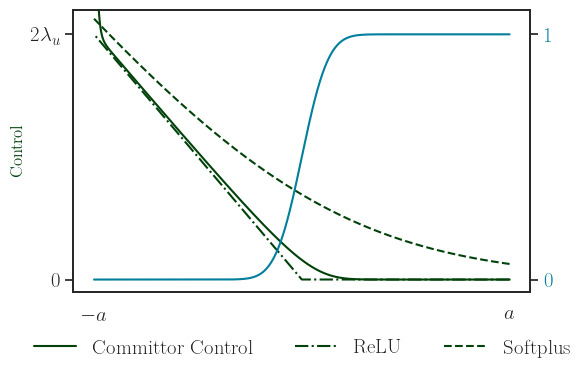

In [5]:
control_color = "#00420A"
committor_color = '#007f9d'

alpha = 1
lambda_u = 1
D = .01 #alpha * lambda_u  
r = lambda_u/(2*D)
print(f"D = {D:.2f}, r = {r:.2f}")
a = 1
xs = np.linspace(-a, a, 5000)
del_committor = np.exp(-r*xs**2)/ (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))
committor = (special.erf(xs*np.sqrt(r)) - special.erf(-a*np.sqrt(r))) / (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))

# make control a function of x
def control_function(x, r: float, D: float, a: float) -> Union[float, np.ndarray]:
    numerator = np.exp(-r*x**2)  #/ (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))
    committor = (special.erf(x*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))# / (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))
    return  numerator / committor *2*D

def control_function(x: Union[float, np.ndarray]) -> Union[float, np.ndarray]:
    Z = special.erf(a * np.sqrt(r)) - special.erf(-a * np.sqrt(r))
    q = (special.erf(x * np.sqrt(r)) - special.erf(-a * np.sqrt(r))) / Z
    numerator = np.exp(-r * x**2) / Z

    # Avoid division by 0 or small q:
    q_safe = np.where(np.abs(q) < 1e-10, np.nan, q)  # or some small ε

    u = numerator / q_safe * D
    return np.nan_to_num(u, nan=0.0)


def control_function_float64(x: np.ndarray, r: float, D: float, a: float) -> np.ndarray:
    x = np.array(x, dtype=np.float64)
    r = np.float64(r)
    Z = special.erf(a * np.sqrt(r)) - special.erf(-a * np.sqrt(r))
    q = (special.erf(x * np.sqrt(r)) - special.erf(-a * np.sqrt(r))) / Z

    log_num = -r * x**2 - np.log(Z)

    eps = 1e-12
    q_safe = np.where(np.abs(q) < eps, np.nan, q)

    u = np.exp(log_num) / q_safe * D
    u = np.nan_to_num(u, nan=0.0, posinf=0.0, neginf=0.0)
    return u

def control_scalar(x: float, r: float, a: float, D:float) -> float:
    integral_val, _ = quad(lambda y: np.exp(-r * y**2), -a, x)
    return 2*D*np.exp(-r * x**2) / integral_val

control_function = np.vectorize(lambda x: control_scalar(x, r, a, D))

control = control_function(xs)


fig, ax1 = plt.subplots(figsize=(6, 4))
ax2 = ax1.twinx()

# Plotting
ax1.plot(xs[25:], control[25:], color=control_color, label='Committor Control')
ax2.plot(xs, committor, color=committor_color, label='Committor')
#ax2.plot(xs, del_committor, '--', label=r'$\nabla q$')  #

#plot linear line y=2rx
intersect = control[1000]
#ax1.plot(xs, - 2*lambda_u * xs, color='green', linestyle='--', label=r'$2\lambda_u$')
#ax1.plot(-xs, intersect+1/2*r * xs**2, color='red', linestyle='--', label=r'$2rx$')

#plot relu
ax1.plot(-xs, np.maximum(0, 2*lambda_u * xs), color=control_color, linestyle='-.', label='ReLU')

#plot softplus
ax1.plot(xs, np.log(1 + np.exp(- 2 *lambda_u * xs)), color=control_color, linestyle='--', label='Softplus') #$2\lambda_u \log(1 + e^{2\lambda_u x})$

# X-axis
ax1.set_xlabel('$u$')
ax1.set_xlabel('')
ax1.set_xticks([-a, a])
ax1.set_xticklabels(['$-a$', '$a$'], fontsize=15)
ax1.set_ylabel('Control', color= control_color)
ax1.set_yticks([0, 2*lambda_u], [0, "$2\lambda_u$"], fontsize=15)


ax2.set_yticks([0, 1])
ax2.tick_params(axis='y', labelcolor= committor_color, labelsize=15)

ax1.set_ylim(-.1, 2.2)
ax2.set_ylim(-.05, 1.1)
ax1.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False, fontsize=15)

plt.tight_layout()
plt.savefig('figures/committor_control.pdf', dpi=300, bbox_inches='tight')
plt.show()

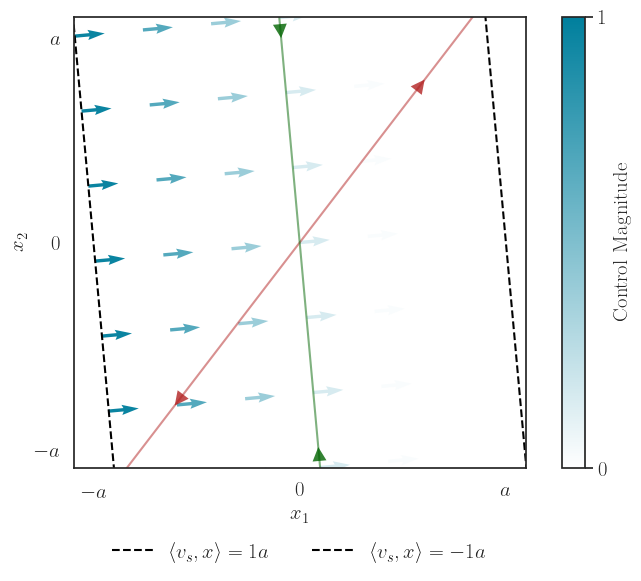

In [6]:
rs = 42  # Random seed for reproducibility
np.random.seed(rs)  
eigenvalues = [lambda_u, -1]
max_T = 50
num_points = 1000
A, Q_mat, Lambda = general_random_matrix_with_fixed_eigendecomposition(2, eigenvalues)
axes_lim = 1.1*a
plot_control_effect_modal(A, a=a, control_function=control_function, Q_mat=Q_mat, xlim=(-axes_lim, axes_lim), ylim=(-axes_lim, axes_lim))


C:\Users\abel_\AppData\Local\Temp\ipykernel_28780\379705015.py:14: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('turbo', nDs+2)


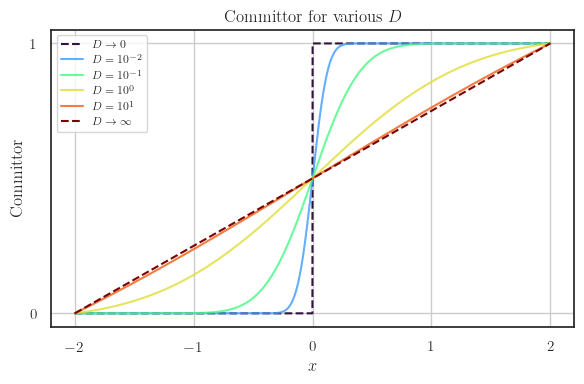

In [7]:

# Parameters
a = 2
lambda_u = 1.0
x_num = 2500
xs = np.linspace(-a, a, x_num)

D_logmin = -2  # log10 of minimum D
D_logmax = 1  # log10 of maximum D
nDs = D_logmax - D_logmin + 1 # number of D values
Ds = np.logspace(D_logmin, D_logmax, nDs)  
rs = lambda_u / (2 * Ds)

# Create color map with 8 colors, first for D=0, last for D=∞
cmap = cm.get_cmap('turbo', nDs+2)
colors = [cmap(i) for i in range(nDs+2)]

fig, ax = plt.subplots(figsize=(6, 4))

# D -> 0: step function
ax.plot(xs, np.heaviside(xs, 0.5), color=colors[0], linestyle='--', label='$D \\to 0$')
# Plot numerical committors for intermediate D
for i, (D, r) in enumerate(zip(Ds, rs), start=1):  # use colors[1] to colors[4]
    committor = (special.erf(xs * np.sqrt(r)) - special.erf(-a * np.sqrt(r))) / \
                (special.erf(a * np.sqrt(r)) - special.erf(-a * np.sqrt(r)))
    ax.plot(xs, committor, color=colors[i], label=f'$D=10^{{{int(np.log10(D))}}}$', alpha=0.8)

# D -> ∞: linear function
ax.plot(xs, (xs + a) / (2 * a), color=colors[-1], linestyle='--', label='$D \\to \\infty$')

# Labels and legend
ax.set_xlabel('$x$')
ax.set_ylabel('Committor')
ax.set_title('Committor for various $D$')
ax.legend(loc='best', fontsize=8)
ax.grid(True)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.savefig('figures/committor_Dscaling.png', dpi=300, bbox_inches='tight')
plt.savefig('figures/committor_Dscaling.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
mpmath.mp.dps = 200  # decimal places
from mpmath import mp, mpf, sqrt, erf, exp, fabs


def high_precision_committor(x: float, a: float, r: float) -> float:
    sqrt_r = mpmath.sqrt(r)
    x, a = mpmath.mpf(x), mpmath.mpf(a)
    
    erf_x = mpmath.erf(x * sqrt_r)
    erf_min = mpmath.erf(-a * sqrt_r)
    erf_max = mpmath.erf(a * sqrt_r)
    
    Z = erf_max - erf_min
    q = (erf_x - erf_min) / Z
    return q

#inefficient version
# def high_precision_control(x: float, a: float, r: float, D: float) -> float:
#     sqrt_r = mpmath.sqrt(r)
#     x, a, r, D = map(mpmath.mpf, [x, a, r, D])

#     erf_min = mpmath.erf(-a * sqrt_r)
#     erf_max = mpmath.erf(a * sqrt_r)
#     Z = erf_max - erf_min

#     q = (mpmath.erf(x * sqrt_r) - erf_min) / Z
#     num = mpmath.exp(-r * x**2) / Z

#     if mpmath.fabs(q) < mpmath.mpf('1e-200'):
#         return mpmath.mpf(0)
#     else:
#         return num / q * D
    

def high_precision_control(xs: np.ndarray, a: float, r: float, D: float, precision: int = 50) -> np.ndarray:
    """
    Compute high-precision control values using mpmath for integration and exponentiation.
    
    Parameters:
        xs : np.ndarray
            Points at which to evaluate the control.
        a : float
            Integration limit (-a to x).
        r : float
            Rate parameter in the exponential.
        D : float
            Scaling constant.
        precision : int
            Decimal precision for mpmath.

    Returns:
        np.ndarray of control values, dtype float64, filled with np.nan where integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)

    control_exact = np.zeros_like(xs, dtype=np.float64)

    for i, x in enumerate(xs):
        x_mpf = mpmath.mpf(x)

        # Define the integrand
        integrand = lambda y: mpmath.exp(-r_mpf * y**2)

        # High-precision definite integral
        try:
            integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
        except Exception:
            integral_val = mpmath.mpf(0)

        if mpmath.fabs(integral_val) > mpmath.mpf('1e-200'):
            numerator = D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
            control_exact[i] = float(numerator / integral_val)
        else:
            control_exact[i] = np.nan

    return control_exact

In [9]:
all_control_vals = []
for i, (D, r) in enumerate(zip(Ds, rs), start=1):  # use colors[1] to colors[6]
    print(f"Calculating control for D={D:.2e}, r={r:.2e} ({i}/{len(Ds)})")

    #more precision, but still not accurate enough! (overflows)
    # control_vals = float(high_precision_control(xs, a=a, r=r, D=D))
    # all_control_vals.append(control_vals)

    control_exact = np.zeros_like(xs, dtype=np.float64)
    for j, x in enumerate(xs):
        integral_val, _ = quad(lambda y: np.exp(-r * y**2), -a, x)
        if integral_val != 0:
            control_exact[j] = D * np.exp(-r * x**2) / integral_val
        else:
            control_exact[j] = np.nan
        #control_exact[i] = D*np.exp(-r * x**2) / integral_val
    all_control_vals.append(control_exact)

Calculating control for D=1.00e-02, r=5.00e+01 (1/4)
Calculating control for D=1.00e-01, r=5.00e+00 (2/4)
Calculating control for D=1.00e+00, r=5.00e-01 (3/4)
Calculating control for D=1.00e+01, r=5.00e-02 (4/4)


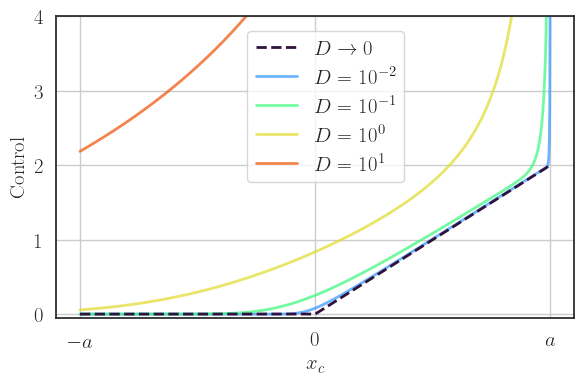

In [11]:

fig, ax = plt.subplots(figsize=(6, 4))

# D -> 0: committor is step function, control is 0? that doesn't seem right
# ax.plot(xs, np.zeros_like(xs), color=colors[0], linestyle='--', label='$D \\to 0$')
# ax.vlines(x=-a, ymin=0, ymax=2, color=colors[0], linestyle='--')
# ax.plot(-np.linspace(-a,0), -np.linspace(-a,0)*lambda_u, color=colors[0], linestyle='--', label='$D \\to 0$', linewidth=2, zorder=10)
# ax.hlines(y=0, xmin=-a, xmax=0, color=colors[0], linestyle='--', linewidth=2, zorder=10)

#plot relu
ax.plot(xs, np.maximum(0, xs * lambda_u), color=colors[0], linestyle='--', label='$D \\to 0$', linewidth=2, zorder=10)

# Plot numerical committors for intermediate D
for i, control_vals in enumerate(all_control_vals, start=1):  # use colors[1] to colors[4]
    D = Ds[i-1]
    ax.plot(-xs[1:], control_vals[1:], color=colors[i], label=f'$D=10^{{{int(np.log10(D))}}}$', alpha=0.75, linewidth=2)

# D -> ∞: committor is a linear function, control is c/(u+d)
#ax.plot(xs[:], 1/(xs[:]+a), color=colors[-1], linestyle='--', label='$D \\to \\infty$')
#not correct to calculate control from the asymptotics of the committor.

#plot softplus
# r = lambda_u / (2 * Ds[1])  # use the last D for the softplus
# ax.plot(xs, 2*Ds[1]*np.log(1 + np.exp(r * xs)), color='purple', linestyle='--', label=r'$2\lambda_u \log(1 + e^{2\lambda_u x})$', linewidth=2)

#plot average of relu and softplus
# xs = np.linspace(-a, a, 50)
# r = lambda_u / (2 * Ds[1])  
# relu_vals = np.maximum(0, xs * lambda_u)
# softplus_vals = 2 * Ds[1] * np.log(1 + np.exp(r * xs))
# avg_vals = 0.5 * (relu_vals + softplus_vals)
# ax.plot(xs, avg_vals, 'x', color=colors[1], label='Average of ReLU and Softplus', linewidth=2)

# Labels and legend
ax.set_xlabel('$x_c$', fontsize=15)
ax.set_ylabel('Control', fontsize=15)
#ax.set_title('Control for varying values of the noise strength $D$') # Control for different magnitudes of stochastic forcing $D$
ax.legend(loc='center', fontsize=15, bbox_to_anchor=(.52, .7))
ax.grid(True)
ax.set_ylim(-0.05, 4)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
#set fontsize ticks
ax.set_xticks([-a, 0, a], [r'$-a$', r'$0$', r'$a$'], fontsize=15)
ax.set_yticks([0,1,2,3,4], [0,1,2,3,4], fontsize=15)

plt.tight_layout()
plt.savefig('figures/committor_control_Dscaling.png', dpi=300, bbox_inches='tight')
plt.savefig('figures/committor_control_Dscaling.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Varying lambda_u

In [488]:
D = 0.1
# Plot the control for different lambda_u values and D=0.1
lambda_logmin = -2  # log10 of minimum D
lambda_logmax = 1  # log10 of maximum D
nlambdas = lambda_logmax - lambda_logmin + 1 # number of D values
lambda_us = np.logspace(lambda_logmin, lambda_logmax, nlambdas)  
# add 0 to lambda_us
lambda_us = np.insert(lambda_us, 0, 0.0)  # add 0 for D=0 case
rs = lambda_us/ (2 * D)

all_control_vals = []
for i, lambda_u in enumerate(lambda_us, start=1):
    r = lambda_u / (2 * D)
    print(f"Calculating control for λ={lambda_u:.2e}, r={r:.2e} ({i}/{len(lambda_us)})")
    control_vals = high_precision_control(xs, a=a, r=r, D=D)
    all_control_vals.append(control_vals)

Calculating control for λ=0.00e+00, r=0.00e+00 (1/5)
Calculating control for λ=1.00e-02, r=5.00e-02 (2/5)
Calculating control for λ=1.00e-01, r=5.00e-01 (3/5)
Calculating control for λ=1.00e+00, r=5.00e+00 (4/5)
Calculating control for λ=1.00e+01, r=5.00e+01 (5/5)


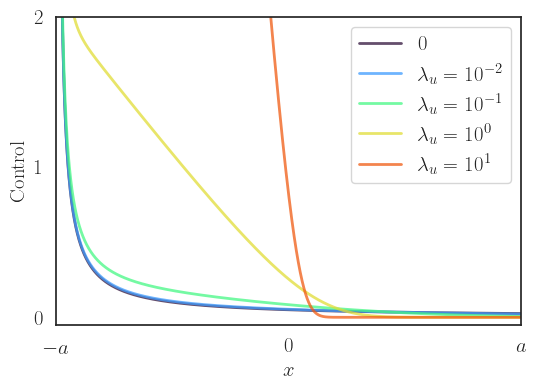

In [489]:
fig, ax = plt.subplots(figsize=(6, 4))
for i, control_vals in enumerate(all_control_vals, start=0):  # use colors[1] to colors[4]
    lambda_u = lambda_us[i]
    ax.plot(xs, control_vals, color=colors[i], label=f'$\\lambda_u=10^{{{int(np.log10(lambda_u))}}}$' if lambda_u!=0 else "0", alpha=0.75, linewidth=2)
ax.set_ylim(-0.05, 2)
ax.set_xlim(-a, a)
ax.set_xlabel('$x$', fontsize=15)
ax.set_ylabel('Control', fontsize=15)
ax.set_xticks([-a, 0, a], [r'$-a$', r'$0$', r'$a$'], fontsize=15)
ax.set_yticks([0, 1, 2], [r'$0$', r'$1$', r'$2$'], fontsize=15)
ax.legend(loc='best', fontsize=15)
plt.savefig('figures/committor_control_lambda_scaling.pdf', dpi=300, bbox_inches='tight')

In [306]:

# x = np.linspace(-a, a, 1000)
# dx = x[1] - x[0]

# # Define the integrand, avoid division by zero
# def integrand_func(x: np.ndarray, r: float) -> np.ndarray:
#     eps = 1e-12
#     y = x.copy()
#     mask = np.abs(y) > eps
#     integrand = np.zeros_like(y)
#     integrand[mask] = np.exp(-r * y[mask]**2) / (2 * r * y[mask]**2)
#     return integrand


# # Plotting
# fig, ax = plt.subplots(figsize=(6, 4))
# for D, r in zip(Ds, rs):
#     integrand = integrand_func(x, r)
#     F = cumtrapz(integrand, x, initial=0)  # Cumulative integral
#     ax.plot(x, F, label=f"$D={D}$", alpha=0.8)
# #ax.plot(x, F, label=r"$\int_{-a}^{u} \frac{e^{-r x^2}}{2r x^2} dx$", color='purple')
# ax.set_xlabel(r"$u$")
# ax.set_ylabel(r"$F(u)$")
# ax.set_title("Integral of $e^{-r x^2} / (2r x^2)$ from $-a$ to $u$")
# ax.legend()
# ax.grid(True)
# plt.tight_layout()
# plt.show()

In [24]:
# ## Plotting the control function and its approximations
# a = 2
# xs = np.linspace(-a, a, x_num)
# D = .01
# r = lambda_u / (2 * D)
# control_exact = np.zeros_like(xs)

# for i, x in enumerate(xs):
#     integral_val, _ = quad(lambda y: np.exp(-r * y**2), -a, x)
#     control_exact[i] = np.exp(-r * x**2) / integral_val
# control_full = control_function_float64(xs, r, D, a)
# control_full[0] = np.nan
# # approximations
# ## 
# control_approx1 = D*np.exp(-r * xs**2) / (-np.exp(-r*xs**2)/(2*r*xs))
# control_approx1 = -2*r*xs*D
# control_approx2 = D*np.exp(-r * xs**2) / (-np.exp(-r*xs**2)/(2*r*xs)+np.exp(-r*a**2)/(2*r*a))
# integrand = integrand_func(xs, r)
# F = cumtrapz(integrand, xs, initial=0)  # xs must start at -a
# control_approx3 = D*np.exp(-r * xs**2) / (    -np.exp(-r * xs**2)/(2*r*xs) + np.exp(-r*a**2)/(2*r*a) - F)
# control_approx3[int(x_num/2):] = np.nan

# fig, ax = plt.subplots(figsize=(6, 4))
# ax.plot(xs[1:], all_control_vals[0][1:], color='purple', label='Exact $(De^{-ru^2}/\int_{-a}^{u}e^{-ry^2}dy)$')
# ax.plot(xs, control_approx1, color='red', linestyle='-', label=r'Linear $(2Drx)$')
# ax.plot(xs, control_approx2, color='green', linestyle='--', label='$De^{-ru^2}/((2Drx)e^{-ru^2}+e^{-ra^2}$')
# ax.plot(xs, control_approx3, color='magenta', linestyle='--', label='Full, but decomposed')
# ax.set_xlim(-.1*a, .1*a)
# ax.set_ylim(0, .1*a)
# ax.legend()

In [310]:
# fig, ax = plt.subplots(figsize=(6, 4))

# # Main plot
# ax.plot(xs[1:], all_control_vals[0][1:], color='purple', label='Exact')
# ax.plot(xs, control_approx1, color='red', linestyle='-', label='Linear $(2\lambda_ux)$')
# ax.plot(xs, control_approx2, color='green', linestyle='--', label='Approximation 2')
# #ax.plot(xs, control_approx3, color='magenta', linestyle='--', label='Approximation 3')
# ax.set_ylim(0, 2*a)
# ax.set_xlabel('$x$')
# ax.set_ylabel('Control')
# ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=5)

# # Inset axes (zoomed-in region)
# axins = inset_axes(ax, width="35%", height="35%", loc='upper right', borderpad=3)  # position inset
# axins.plot(xs[1:], all_control_vals[0][1:], color='purple')
# axins.plot(xs, control_approx1, color='red', linestyle='-')
# axins.plot(xs, control_approx2, color='green', linestyle='--')
# x1, x2 = -0.1, 0.1
# y1, y2 = 0, 0.1
# axins.set_xlim(x1, x2)
# axins.set_ylim(y1, y2)
# axins.set_xticks([-0.2, 0, 0.2])
# axins.set_yticks([0, 0.1])
# axins.set_xticks([])
# axins.set_yticks([])
# mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5");

# axins2 = inset_axes(ax, width="35%", height="35%", loc='upper left', borderpad=3)  #
# axins2.plot(xs[1:], all_control_vals[0][1:], color='purple')
# axins2.plot(xs, control_approx1, color='red', linestyle='-')
# axins2.plot(xs, control_approx2, color='green', linestyle='--')
# x1, x2 = -1.0*a, -.95*a
# y1, y2 = .9*a, 1.1*a
# axins2.set_xlim(x1, x2)
# axins2.set_ylim(y1, y2)
# axins2.set_xticks([x1, x2])
# axins2.set_yticks([y1, y2])
# axins2.set_xticks([])
# axins2.set_yticks([])
# mark_inset(ax, axins2, loc1=2, loc2=4, fc="none", ec="0.5");

### Empirical committor

In [12]:
rs = 42  # Random seed for reproducibility
np.random.seed(rs)  
eigenvalues = [lambda_u, -1]
max_T = 50
num_points = 1000
A, Q_mat, Lambda = general_random_matrix_with_fixed_eigendecomposition(2, eigenvalues)
ts, traj_ol = simulate_system(A, x0=np.array([4.0, 4.0]), t_span=(0, 5))

nsims = 100  # Number of simulations
trajs = np.zeros((nsims, num_points, 2))
x0s = []
x0s = sample_initial_conditions_between_sets(Q=Q_mat, Lambda=eigenvalues, a=a, b=a, nsims=nsims, seed=42)

for i,x0 in enumerate(x0s):
    ts, traj_noisy, noise = simulate_system_noisy(A, D=D, x0=x0, t_span=(0,max_T), num_points=num_points, random_seed=rs+i)
    trajs[i, :, :] = traj_noisy

# fig, ax = plt.subplots(figsize=(4, 4))

plot_eigendirections(ax, Q_mat, Lambda, a=a)
plot_set_boundaries(ax, a, Q_mat, Lambda)
for i in range(nsims):
    #ax.plot(ts, trajs[0, i, :], color='C0', alpha=.1)
    ax.plot(trajs[i, :, 0], trajs[i, :, 1], color='C0', alpha=.1)
    #ax.plot(trajs[i, -1, 0], trajs[i, -1, 1], 'o', color='C2', markersize=2, zorder=1000) #final point

ax.set_xlim(-2*a, 2*a)
ax.set_ylim(-2*a, 2*a);
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=2)

In [13]:
bin_centers, committor_vals, n_uncommitted = compute_empirical_committor_projection(trajs, A, Q_mat, Lambda, a, bin_edges=np.linspace(-a*1.25, a*1.25, 16))
bin_centers_control, committor_vals_control, n_uncommitted_control = compute_empirical_committor_projection(trajs_control, A, Q_mat, Lambda, a, bin_edges=np.linspace(-a*1.25, a*1.25, 16))

sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 4))
#plot histogram of committor values
ax.hist(bin_centers_control, bins=bin_centers_control, weights=committor_vals_control, alpha=0.5, color='C1', label='Control')
ax.hist(bin_centers, bins=bin_centers, weights=committor_vals, alpha=0.5, color='C0', label='Autonomous')
#ax.plot(bin_centers_control, committor_vals_control, marker='o', linestyle='-', color='C1', label='Control')
ax.plot(-xs, committor, '--', color='C2', label='Theoretical Committor')
ax.set_xlabel('Projection onto unstable eigendirection')
ax.set_ylabel('Committor')
ax.legend()

NameError: name 'trajs_control' is not defined

### Finding the left eigenvector

In [27]:
tau = .9
w = np.random.uniform(-1, 1, size=2)
for t, xt in enumerate(trajs[1, :, :]):
    w = tau*w + (1-tau)*(np.dot(w, xt))*xt
    w = w / np.linalg.norm(w)  

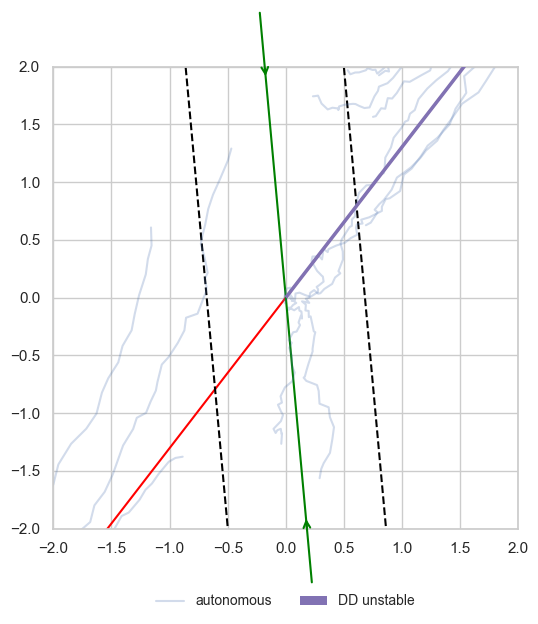

In [72]:
fig, ax = plt.subplots(figsize=(6, 6))

plot_eigendirections(ax, Q_mat, Lambda, label=False)
plot_set_boundaries(ax, a, Q_mat, Lambda, label=False)
for i in range(10):
    #ax.plot(ts, trajs[0, i, :], color='C0', alpha=.1)
    ax.plot(trajs[i, :, 0], trajs[i, :, 1], color='C0', alpha=.25, label='autonomous' if i == 0 else "")
    #ax.plot(trajs_control[0, i, :], trajs_control[1, i, :], color='C1', alpha=.25, label='control' if i == 0 else "")
ax.quiver(0, 0, w[0], w[1], angles='xy', scale_units='xy', scale=.1, color='C4', label='DD unstable', zorder=10000)
ax.set_xlim(-2*a, 2*a)
ax.set_ylim(-2*a, 2*a)
ax.legend(loc='lower center', fontsize=10, bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

In [74]:
# make video


def update(frame):
    #plot the trajectory up to frame
    
    tau = .99
    traj_idx = 2
    np.random.seed(traj_idx)  # Reset random seed for reproducibility
    w = np.random.uniform(-1, 1, size=2)
    for t, xt in enumerate(trajs[traj_idx, :frame, :]):
        w = tau*w + (1-tau)*(np.dot(w, xt))*xt
        w = w / np.linalg.norm(w)  

    ax.clear()
    plot_eigendirections(ax, Q_mat, Lambda, label=False)
    plot_set_boundaries(ax, a, Q_mat, Lambda, label=False)
    
    #for i in range(frame):
    ax.plot(trajs[traj_idx, :frame, 0],         trajs[traj_idx, :frame, 1],         color='C0', alpha=.25)
    ax.plot(trajs_control[traj_idx, :frame, 0], trajs_control[traj_idx, :frame, 1], color='C1', alpha=.25)
    ax.quiver(0, 0, w[0], w[1], angles='xy', scale_units='xy', scale=.1, color='C4', label='DD unstable', zorder=10000)

    ax.set_xlim(-2*a, 2*a)
    ax.set_ylim(-2*a, 2*a)

    ax.set_title(f"Frame {frame + 1}")
    ax.legend(loc='lower center', fontsize=10, bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

ani = FuncAnimation(fig, update, frames=100, repeat=False, interval=100)

In [75]:
HTML(ani.to_jshtml())

In [76]:
ani.save("saddle_top_eigv.mp4", writer='ffmpeg')

In [116]:
# def update_v_inout(v, traj):
#     x_init = traj[0, :]
#     x_final = traj[-1, :]

#     v -= np.dot(v, x_final) * x_final - np.dot(v, x_init) * x_init
#     v /= np.linalg.norm(v)
#     return v

def update_v_inout(v, x_init, x_final, gamma=1):
    v = v + gamma * (-np.dot(v, x_init) * v + np.dot(v, x_final) * x_final)
    v /= np.linalg.norm(v)
    return v

def traj_into_nbhd(traj, eps):
    # Check when the trajectory enters in the neighborhood of the saddle point
    #return entry and exit points 
    traj = np.array(traj)
    # return None if the trajectory never enters the neighborhood
    entry_idx = np.where(np.linalg.norm(traj, axis=1) < eps)[0]
    if entry_idx.size == 0:
        return None, None
    entry_idx = entry_idx[0]  # take the first entry point
    if entry_idx == 0:
        return None, None
    #exit should come after entry
    traj_afterin = traj[entry_idx:]  # slice the trajectory from the entry point
    exit_idx = np.where(np.linalg.norm(traj_afterin, axis=1) > eps)[0]
    if exit_idx.size == 0:
        return entry_idx, None
    exit_idx = exit_idx[0] + entry_idx  # add the entry index to the exit index

    return traj[entry_idx], traj[exit_idx]  

def v_from_trajs_inout(trajs, eps):
    v = np.random.uniform(-1, 1, size=2)
    v /= np.linalg.norm(v)  # normalize the vector
    for traj in trajs:
        x_init, x_final = traj_into_nbhd(traj, eps=eps)
        if x_init is not None and x_final is not None:
            v = update_v_inout(v, x_init, x_final)
    return v

#v = v_from_trajs_inout(trajs, eps=1)


C:\Users\abel_\AppData\Local\Temp\ipykernel_29376\2133315853.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap('PuOr', trajs.shape[0])


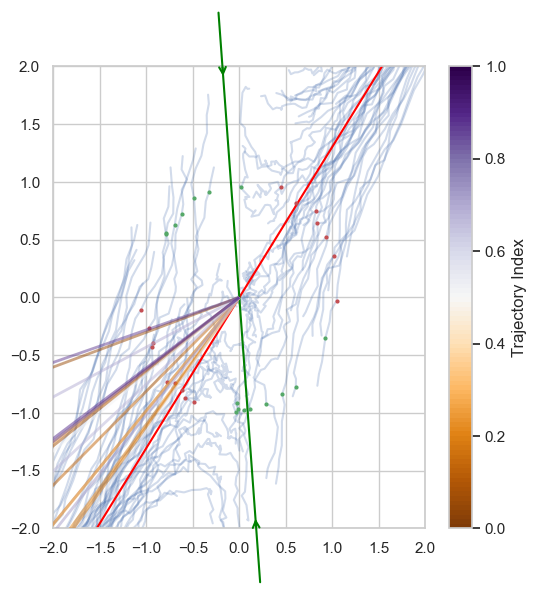

In [ ]:
rs = 423
np.random.seed(rs)  # Reset random seed for reproducibility
v = np.random.uniform(-1, 1, size=2)
v /= np.linalg.norm(v)

eps = 1
# colormap for updated v
colormap = cm.get_cmap('PuOr', trajs.shape[0])
fig, ax = plt.subplots(figsize=(6, 6))
for traj_i, traj in enumerate(trajs):
    x_init, x_final = traj_into_nbhd(traj, eps=eps)
    ax.plot(traj[:, 0], traj[:, 1], color='C0', alpha=.25)
    if x_init is not None and x_final is not None:
        ax.plot(x_init[0], x_init[1], 'o', color='C2', markersize=2, zorder=1000)  # initial point
        ax.plot(x_final[0], x_final[1], 'o', color='C3', markersize=2, zorder=1000)  # final point
        v = update_v_inout(v, x_init, x_final)
        ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=.1, color=colormap(traj_i), label='DD unstable', zorder=10000, alpha=0.5)

plot_eigendirections(ax, Q_mat, Lambda, label=False)
ax.set_xlim(-2*a, 2*a)
ax.set_ylim(-2*a, 2*a)
ax.set_aspect('equal', adjustable='box')
sm = cm.ScalarMappable(cmap=colormap)
cbar = fig.colorbar(sm, ax=ax, label='Trajectory Index')

In [143]:
rs = 42  
np.random.seed(rs)  
eigenvalues = [lambda_u, -1]
max_T = 5
num_points = 1000
A, Q_mat, Lambda = general_random_matrix_with_fixed_eigendecomposition(2, eigenvalues)
#ts, traj_ol = simulate_system(A, x0=np.array([4.0, 4.0]), t_span=(0, 5))

nsims = 1000  # Number of simulations
trajs = np.zeros((nsims, num_points, 2))
x0s = []
x0s = sample_initial_conditions_between_sets(Q=Q_mat, Lambda=eigenvalues, a=2*a, b=2*a, nsims=nsims, seed=42)

for i,x0 in enumerate(x0s):
    ts, traj_noisy, noise = simulate_system_noisy(A, D=D, x0=x0, t_span=(0,max_T), num_points=num_points, random_seed=rs+i)
    trajs[i, :, :] = traj_noisy

C:\Users\abel_\AppData\Local\Temp\ipykernel_29376\1811520484.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = cm.get_cmap('PuOr', trajs.shape[0])


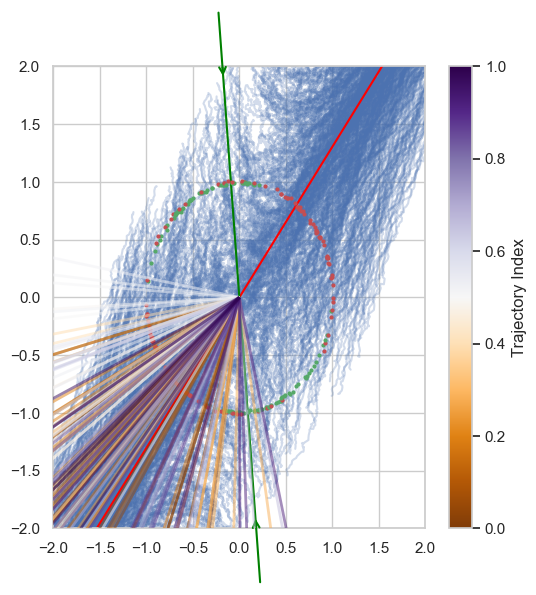

In [ ]:
v = np.random.uniform(-1, 1, size=2)
v /= np.linalg.norm(v)

eps = 1
# colormap for updated v
colormap = cm.get_cmap('PuOr', trajs.shape[0])
fig, ax = plt.subplots(figsize=(6, 6))
vs = np.zeros((trajs.shape[0], 2))
for traj_i, traj in enumerate(trajs):
    x_init, x_final = traj_into_nbhd(traj, eps=eps)
    ax.plot(traj[:, 0], traj[:, 1], color='C0', alpha=.25)
    if x_init is not None and x_final is not None:
        ax.plot(x_init[0], x_init[1], 'o', color='C2', markersize=2, zorder=1000)  # initial point
        ax.plot(x_final[0], x_final[1], 'o', color='C3', markersize=2, zorder=1000)  # final point
        v = update_v_inout(v, x_init, x_final)
        vs[traj_i, :] = v
        ax.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=.1, color=colormap(traj_i), label='DD unstable', zorder=10000, alpha=0.5)

plot_eigendirections(ax, Q_mat, Lambda, label=False)
ax.set_xlim(-2*a, 2*a)
ax.set_ylim(-2*a, 2*a)
ax.set_aspect('equal', adjustable='box')

sm = cm.ScalarMappable(cmap=colormap)
cbar = fig.colorbar(sm, ax=ax, label='Trajectory Index')

C:\Users\abel_\AppData\Local\Temp\ipykernel_29376\3112076096.py:3: RuntimeWarning: invalid value encountered in divide
  vs_unit = vs / np.linalg.norm(vs, axis=1, keepdims=True)


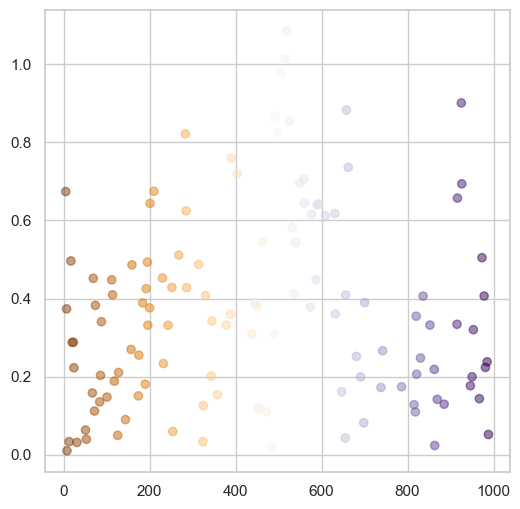

In [159]:
fig, ax = plt.subplots(figsize=(6, 6))
#plot angle between v and unstable direction
vs_unit = vs / np.linalg.norm(vs, axis=1, keepdims=True)
v_u = np.real(Q_mat[:, 0])
v_u_unit = -v_u / np.linalg.norm(v_u)
cos_angles = np.clip(
    np.einsum('ij,j->i', vs_unit, v_u_unit),
    -1.0, 1.0
)
angles = np.arccos(cos_angles)  # angles in radians
ax.scatter(np.arange(vs.shape[0]), angles, c=colormap(np.arange(vs.shape[0])), alpha=0.5)

In [14]:

def plot_committor_2d(
    a: float,
    committor_vals_2d: np.ndarray,
    bin_centers_2d: np.ndarray,
    counts_2d: Optional[np.ndarray] = None,
    count_threshold: int = 5,
    title: Optional[str] = None,
    ax: Optional[plt.Axes] = None,
    fontsize: int=15,
    Q_mat: Optional[np.ndarray] = None,
    Lambda: Optional[np.ndarray] = None,
    save_name: Optional[str] = None,
    ccn_cmap = ccn_cmap
) -> None:
    """
    Plot 2D committor values as a heatmap.

    Args:
        a: Projection threshold used to define the committor boundary
        committor_vals_2d: Array of committor probabilities (ny, nx)
        bin_centers_2d: Array of bin center coordinates (ny, nx, 2)
        counts_2d: Optional array of sample counts per bin (ny, nx)
        count_threshold: Minimum number of samples in a bin to show its value
        title: Title for the plot
        ax: Optional matplotlib Axes to plot on; if None, a new figure is created
        Q_mat: Optional eigenvector matrix for plotting eigendirections
        Lambda: Optional eigenvalue matrix for plotting eigendirections
    """
    ny, nx = committor_vals_2d.shape
    X = bin_centers_2d[..., 0]
    Y = bin_centers_2d[..., 1]
    Z = committor_vals_2d.copy()

    if counts_2d is not None:
        Z = np.where(counts_2d >= count_threshold, Z, np.nan)

    # Create figure and axis if none provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    #cmap = plt.cm.viridis
    pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=ccn_cmap, vmin=0.0, vmax=1.0)
    cbar = plt.colorbar(pc, ax=ax, label="Empirical Committor")
    cbar.ax.tick_params(labelsize=fontsize)  # for tick labels
    cbar.set_label("Empirical Committor", fontsize=fontsize)  # for colorbar label
    
    ax.set_xlabel('$x_1$', fontsize=fontsize)
    ax.set_ylabel('$x_2$', fontsize=fontsize)
    if title:
        ax.set_title(title, fontsize=fontsize)
    ax.set_aspect('equal')
    ax.set_xlim(-1.1 * a, 1.1 * a)
    ax.set_ylim(-1.1 * a, 1.1 * a)
    #ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    #ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xticks([-a, 0, a])
    ax.set_yticks([-a, 0, a])
    ax.set_xticklabels(['$-a$', '0', '$a$'], fontsize=fontsize)
    ax.set_yticklabels(['$-a$', '0', '$a$'], fontsize=fontsize)

    # Optionally plot eigendirections and boundaries
    if Q_mat is not None and Lambda is not None:
        plot_set_boundaries(ax, a, Q_mat, Lambda, label=False)
        plot_eigendirections(ax, Q_mat, Lambda, a=a, label=False)

    if save_name:
        plt.savefig(save_name, dpi=300, bbox_inches='tight')

    if ax is None:
        plt.tight_layout()
        plt.show()


def plot_committor_1d_from_2d_projection(
    committor_vals_2d: np.ndarray,
    bin_centers_2d: np.ndarray,
    Q: np.ndarray,
    Lambda: np.ndarray,
    num_bins: int = 40,
    count_threshold: int = 1,
    counts_2d: Optional[np.ndarray] = None,
    theoretical_committor: Optional[np.ndarray] = None,
    tc_xs: Optional[np.ndarray] = None,
    show: bool = True
):
    """
    Project the 2D committor onto the unstable direction and plot as 1D.

    Args:
        committor_vals_2d: shape (ny, nx)
        bin_centers_2d: shape (ny, nx, 2)
        Q: eigenvector matrix of A
        Lambda: diagonal matrix of eigenvalues
        num_bins: number of bins along unstable projection axis
        count_threshold: ignore 2D bins with fewer samples than this
        counts_2d: optional (ny, nx) array with trajectory counts per bin
        show: if True, call plt.show()
    """
    eigvals = np.diag(Lambda)
    unstable_idx = np.argmax(np.real(eigvals))
    v_u = np.real(Q[:, unstable_idx])
    v_u /= np.linalg.norm(v_u)

    # Flatten data
    ny, nx = committor_vals_2d.shape
    centers_flat = bin_centers_2d.reshape(-1, 2)      # shape (ny*nx, 2)
    committor_flat = committor_vals_2d.ravel()        # shape (ny*nx,)
    if counts_2d is not None:
        counts_flat = counts_2d.ravel()
        mask = counts_flat >= count_threshold
    else:
        mask = ~np.isnan(committor_flat)

    centers_flat = centers_flat[mask]
    committor_flat = committor_flat[mask]
    proj_vals = centers_flat @ v_u

    # Bin projections
    proj_min, proj_max = proj_vals.min(), proj_vals.max()
    bin_edges = np.linspace(proj_min, proj_max, num_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_indices = np.digitize(proj_vals, bin_edges) - 1

    committor_1d = np.zeros(num_bins)
    counts_1d = np.zeros(num_bins)

    for val, b in zip(committor_flat, bin_indices):
        if 0 <= b < num_bins:
            committor_1d[b] += val
            counts_1d[b] += 1

    with np.errstate(invalid='ignore'):
        committor_1d = np.where(counts_1d > 0, committor_1d / counts_1d, np.nan)

    # Plot
    plt.figure(figsize=(6, 4))
    plt.plot(bin_centers, committor_1d, 'o-', label='Projected committor')
    plt.plot(tc_xs, theoretical_committor, color='orange', label='Committor')
    plt.xlabel('Projection onto $v_u$')
    plt.ylabel('Committor')
    plt.title('1D Committor Projected from 2D')
    plt.grid(True)
    plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    if show:
        plt.show()


def plot_committor_1d(
    bin_centers_1d: np.ndarray,
    committor_vals_1d: np.ndarray,
    a: float,
    theoretical_committor: Optional[np.ndarray] = None,
    tc_xs: Optional[np.ndarray] = None,
    title: str = 'Empirical Committor (1D)',
    xlabel: str = 'Projection onto $v_s^T$',
    ax: Optional[plt.Axes] = None,
    fontsize: int = 15,
    show: bool = True,
    save_name: Optional[str] = None,
    theoretical_color: str = ccn_color,
    empirical_color: str = '#c30036'
) -> None:
    """
    Plot the 1D empirical committor directly from precomputed values.

    Args:
        bin_centers_1d: Array of shape (num_bins,) – x-axis locations (projection onto v_u)
        committor_vals_1d: Array of shape (num_bins,) – empirical committor values
        theoretical_committor: Optional – values of true committor function (same shape as tc_xs)
        tc_xs: Optional – x values for plotting theoretical committor
        title: Plot title
        xlabel: Label for x-axis
        ax: Optional matplotlib Axes object to plot into
        show: Whether to call plt.show() if ax is None
    """
    # Create figure and axis if not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(bin_centers_1d, committor_vals_1d, 'o-', color=empirical_color, label='Empirical committor')

    if theoretical_committor is not None and tc_xs is not None:
        ax.plot(tc_xs, theoretical_committor, color=theoretical_color, linewidth=2, label='Theoretical committor')

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Committor', fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    #ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xticks([-a, 0, a])
    ax.set_xticklabels(['$-a$', '0', '$a$'], fontsize=fontsize)
    #ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['0', '1'], fontsize=fontsize)
    ax.grid(True)
    ax.set_ylim(-0.05, 1.05)
    ax.legend()

    if save_name:
        plt.savefig(save_name, dpi=300, bbox_inches='tight')

    if ax is None and show:
        plt.tight_layout()
        plt.show()

def plot_committor_1d_histogram(
    bin_centers: np.ndarray,
    empirical_committor: np.ndarray,
    true_committor: Optional[np.ndarray] = None,
    true_committor_xs: Optional[np.ndarray] = None,
    title: str = 'Empirical Committor (1D)',
    xlabel: str = 'Projection onto $v_u$',
    ax: Optional[plt.Axes] = None,
    show: bool = True,
) -> None:
    """
    Plot a 1D histogram of empirical committor values using bin centers,
    with optional overlay of a theoretical committor curve.

    Args:
        bin_centers: (num_bins,) array – centers of bins along the x-axis
        empirical_committor: (num_bins,) array – empirical committor values at each bin
        true_committor: Optional – theoretical committor values
        true_committor_xs: Optional – x values corresponding to the theoretical committor
        title: Title of the plot
        xlabel: Label for the x-axis
        ax: Optional matplotlib Axes object to plot into
        show: Whether to call plt.show() if ax is None
    """
    # Estimate bar width from bin centers
    bin_widths = np.diff(bin_centers)
    width = np.min(bin_widths) if len(bin_widths) > 0 else 0.1

    # Create figure and axis if needed
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.bar(
        bin_centers,
        empirical_committor,
        width=width,
        align='center',
        edgecolor='black',
        alpha=0.8,
        label='Empirical committor'
    )

    if true_committor is not None and true_committor_xs is not None:
        ax.plot(
            true_committor_xs,
            true_committor,
            color='orange',
            linewidth=2,
            label='Theoretical committor'
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Committor')
    ax.set_ylim(0.0, 1.05)
    ax.set_title(title)
    ax.grid(True)
    ax.legend(loc='best', fontsize=fontsize)

    if ax is None and show:
        plt.tight_layout()
        plt.show()

In [15]:
def estimate_empirical_committor_with_early_stopping(
    A_matrix: np.ndarray,
    Q_mat: np.ndarray,
    Lambda: np.ndarray,
    a: float,
    b: float,
    D: float,
    nsims: int,
    num_points: int,
    t_span: Tuple[float, float],
    control_function=None,
    num_bins_1d: int = 20,
    num_bins_2d: int = 40,
    x_range: Tuple[float, float] = (-2, 2),
    y_range: Tuple[float, float] = (-2, 2),
    seed: int = 0
) -> dict:
    """
    Simulate multiple paths and compute 1D + 2D empirical committor functions,
    stopping each path early upon reaching ±a in projection.

    Initial conditions are sampled in the rectangle ⟨v_u, x⟩ ∈ (−a, a), ⟨v_s, x⟩ ∈ (−b, b).

    Returns:
        dict containing 1D and 2D committor statistics and counts
    """
    from copy import deepcopy

    eigvals = Lambda
    unstable_idx = np.argmax(np.real(eigvals))
    stable_idx = np.argmin(np.real(eigvals))

    v_u = np.real(Q_mat[:, unstable_idx])
    v_u /= np.linalg.norm(v_u)
    v_s = np.real(Q_mat[:, stable_idx])
    v_s /= np.linalg.norm(v_s)
    v_s_ortho = np.array([-v_s[1], v_s[0]])  # orthogonal to v_s

    # Use provided sampling method
    x0s_all = sample_initial_conditions_between_sets(Q_mat, Lambda, a, b, nsims, seed)

    x0s = []
    proj0s = []
    hit_minus_before_plus = []
    is_committed = []

    for i in tqdm(range(nsims)):
        rng = np.random.default_rng(seed + i)
        x0 = x0s_all[i]
        x = np.zeros((num_points, 2))
        x[0, :] = x0

        committed = False
        for k in range(1, num_points):
            dt = (t_span[1] - t_span[0]) / (num_points - 1)

            if D > 0:
                dW = rng.standard_normal(size=2) * np.sqrt(dt)
                noise_step = np.sqrt(2 * D) * dW
            else:
                noise_step = np.zeros(2)

            if control_function is not None:
                u = stable_direction_projection(x[k - 1, :], v_u, v_s)
                u_scalar = control_function(u)
                control_input = u_scalar * v_u
            else:
                control_input = np.zeros(2)

            x[k, :] = x[k - 1, :] + dt * (A_matrix @ x[k - 1, :]) + noise_step + control_input

            proj = x[k, :] @ v_u
            if proj < -a:
                x0s.append(x0)
                #proj0s.append(x0 @ v_u)
                proj0s.append(x0 @ v_s_ortho)
                hit_minus_before_plus.append(True)
                is_committed.append(True)
                committed = True
                break
            elif proj > a:
                x0s.append(x0)
                #proj0s.append(x0 @ v_u)
                proj0s.append(x0 @ v_s_ortho)
                hit_minus_before_plus.append(False)
                is_committed.append(True)
                committed = True
                break

        if not committed:
            x0s.append(x0)
            #proj0s.append(x0 @ v_u)
            proj0s.append(x0 @ v_s_ortho)
            hit_minus_before_plus.append(False)
            is_committed.append(False)

    x0s = np.array(x0s)
    proj0s = np.array(proj0s)
    hit_minus_before_plus = np.array(hit_minus_before_plus)
    is_committed = np.array(is_committed)
    n_uncommitted = np.sum(~is_committed)

    bin_edges_1d = np.linspace(proj0s.min(), proj0s.max(), num_bins_1d + 1)
    bin_centers_1d = 0.5 * (bin_edges_1d[:-1] + bin_edges_1d[1:])
    bin_indices = np.digitize(proj0s, bin_edges_1d) - 1  # shape (N,)

    committor_vals_1d = np.zeros(num_bins_1d)
    counts_1d = np.zeros(num_bins_1d)

    for i in range(len(proj0s)):
        b = bin_indices[i]
        if 0 <= b < num_bins_1d and is_committed[i]:
            committor_vals_1d[b] += hit_minus_before_plus[i]
            counts_1d[b] += 1

    with np.errstate(invalid='ignore', divide='ignore'):
        committor_vals_1d = np.where(counts_1d > 0, committor_vals_1d / counts_1d, np.nan)

    # # 1D binning
    # bin_edges_1d = np.linspace(proj0s.min(), proj0s.max(), num_bins_1d + 1)
    # bin_centers_1d = 0.5 * (bin_edges_1d[:-1] + bin_edges_1d[1:])
    # bin_indices = np.digitize(proj0s, bin_edges_1d) - 1
    # committor_vals_1d = np.zeros(num_bins_1d)
    # counts_1d = np.zeros(num_bins_1d)
    # centers_eigbasis = bin_centers_1d @ Q_mat.T
    # proj_vals = centers_eigbasis[:, 0]

    # for i in range(len(x0s)):
    #     b = bin_indices[i]
    #     if 0 <= b < num_bins_1d and is_committed[i]:
    #         committor_vals_1d[b] += hit_minus_before_plus[i]
    #         counts_1d[b] += 1

    # with np.errstate(invalid='ignore'):
    #     committor_vals_1d = np.where(counts_1d > 0, committor_vals_1d / counts_1d, np.nan)

    # 2D binning
    x_edges = np.linspace(x_range[0], x_range[1], num_bins_2d + 1)
    y_edges = np.linspace(y_range[0], y_range[1], num_bins_2d + 1)
    bin_centers_2d = np.stack(np.meshgrid(
        0.5 * (x_edges[:-1] + x_edges[1:]),
        0.5 * (y_edges[:-1] + y_edges[1:])
    ), axis=-1)
    committor_vals_2d = np.zeros((num_bins_2d, num_bins_2d))
    counts_2d = np.zeros((num_bins_2d, num_bins_2d))

    for i in range(len(x0s)):
        x, y = x0s[i, 0], x0s[i, 1]
        xi = np.digitize(x, x_edges) - 1
        yi = np.digitize(y, y_edges) - 1
        if 0 <= xi < num_bins_2d and 0 <= yi < num_bins_2d and is_committed[i]:
            committor_vals_2d[yi, xi] += hit_minus_before_plus[i]
            counts_2d[yi, xi] += 1

    with np.errstate(invalid='ignore'):
        committor_vals_2d = np.where(counts_2d > 0, committor_vals_2d / counts_2d, np.nan)

    ny, nx = committor_vals_2d.shape
    centers_flat = bin_centers_2d.reshape(-1, 2)  # shape (ny*nx, 2)
    committor_flat = committor_vals_2d.ravel()
    counts_flat = counts_2d.ravel()

    mask = counts_flat > 0
    centers_flat = centers_flat[mask]
    committor_flat = committor_flat[mask]

    # Project each 2D bin center onto unstable direction v_u:
    # proj_vals = centers_flat @ v_u
    
    # # Bin these projection values into 1D bins:
    # proj_min, proj_max = proj_vals.min(), proj_vals.max()
    # bin_edges_1d = np.linspace(proj_min, proj_max, num_bins_1d + 1)
    # bin_centers_1d = 0.5 * (bin_edges_1d[:-1] + bin_edges_1d[1:])
    # bin_indices = np.digitize(proj_vals, bin_edges_1d) - 1

    # committor_vals_1d = np.zeros(num_bins_1d)
    # counts_1d = np.zeros(num_bins_1d)

    # for val, b in zip(committor_flat, bin_indices):
    #     if 0 <= b < num_bins_1d:
    #         committor_vals_1d[b] += val
    #         counts_1d[b] += 1

    # with np.errstate(invalid='ignore'):
    #     committor_vals_1d = np.where(counts_1d > 0, committor_vals_1d / counts_1d, np.nan)

    return {
        'bin_centers_1d': bin_centers_1d,
        'committor_vals_1d': committor_vals_1d,
        'bin_centers_2d': bin_centers_2d,
        'committor_vals_2d': committor_vals_2d,
        'counts_2d': counts_2d,
        'n_uncommitted': n_uncommitted
    }


In [16]:
lambda_u = .5
rs = 42  # Random seed for reproducibility
np.random.seed(rs)  
eigenvalues = [lambda_u, -1]
max_T = 50
num_points = 1000
A, Q_mat, Lambda = general_random_matrix_with_fixed_eigendecomposition(2, eigenvalues)

D = 1
r = lambda_u / (2 * D)
a = 2
xs = np.linspace(-a, a, 1000)
committor = (special.erf(xs*np.sqrt(r)) - special.erf(-a*np.sqrt(r))) / (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))

In [17]:
results = estimate_empirical_committor_with_early_stopping(
    A_matrix=A,
    Q_mat=Q_mat,
    Lambda=np.diag(Lambda),
    a=a,
    b=a,
    D=D,
    nsims=50000,
    num_points=500,
    t_span=(0, 100),
    control_function=None,
    x_range=(-a, a),
    y_range=(-a, a),
)

100%|██████████| 50000/50000 [00:05<00:00, 8683.70it/s]


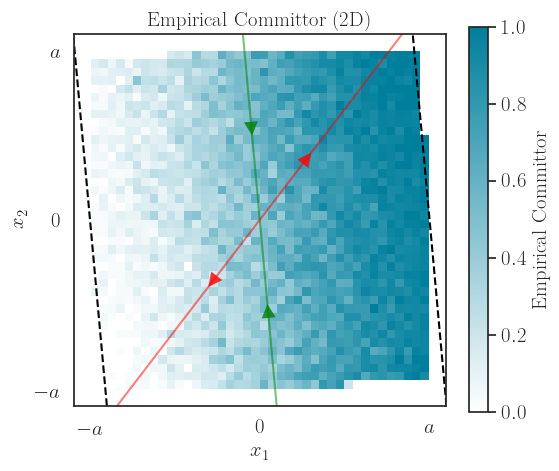

In [18]:
plot_committor_2d(a=a, committor_vals_2d=1-results['committor_vals_2d'], bin_centers_2d=results['bin_centers_2d'], counts_2d=results['counts_2d'], Q_mat=Q_mat, Lambda=Lambda, title='Empirical Committor (2D)', save_name='figures/committor_2d.png')

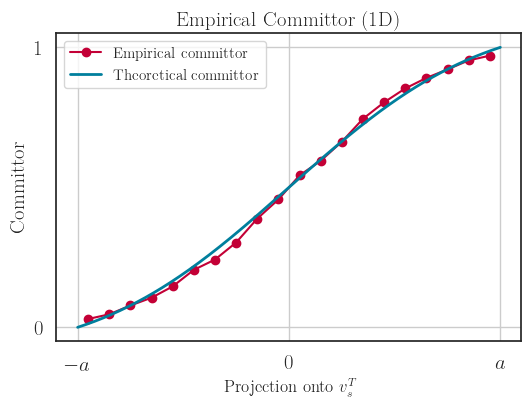

In [56]:
plot_committor_1d(a=a, bin_centers_1d=results['bin_centers_1d'],committor_vals_1d=results['committor_vals_1d'],theoretical_committor=committor[::-1],tc_xs=-xs,save_name='figures/committor_1d.pdf')

### Committor control 

In [9]:
theta = np.pi / 2
A = np.array([
    [1/2, 1 / np.tan(theta)],
    [0, -1/2]
])
eigenvalues, Q_mat = np.linalg.eig(A)
Lambda = np.diag(eigenvalues)
#A - Q_mat @ Lambda @ np.linalg.inv(Q_mat)

D = .05
r = lambda_u / (2 * D)
a = 2
xs = np.linspace(-a, a, 1000)
committor = (special.erf(xs*np.sqrt(r)) - special.erf(-a*np.sqrt(r))) / (special.erf(a*np.sqrt(r)) - special.erf(-a*np.sqrt(r)))

nsims = 5000
time_points = 500
max_T = 100

print("Simulating trajectories for the autonomous system...")
num_bins = 20
num_bins_1d = num_bins
num_bins_2d = num_bins
results_aut = estimate_empirical_committor_with_early_stopping(
    A_matrix=A,
    Q_mat=Q_mat,
    Lambda=np.diag(Lambda),
    a=a,
    b=a,
    D=D,
    nsims=nsims,
    num_points=time_points,
    t_span=(0, max_T),
    control_function=None,
    x_range=(-a*1.0, a*1.0),
    y_range=(-a*1.0, a*1.0),
    num_bins_1d = num_bins_1d,
    num_bins_2d = num_bins_2d
)

print("Simulating trajectories for the controlled system...")
results_control = estimate_empirical_committor_with_early_stopping(
    A_matrix=A,
    Q_mat=Q_mat,
    Lambda=np.diag(Lambda),
    a=a,
    b=a,
    D=D,
    nsims=nsims,
    num_points=time_points,
    t_span=(0, max_T),
    control_function=control_function,
    x_range=(-a*1.0, a*1.0),
    y_range=(-a*1.0, a*1.0),
    num_bins_1d = num_bins_1d,
    num_bins_2d = num_bins_2d
)

Simulating trajectories for the autonomous system...


NameError: name 'estimate_empirical_committor_with_early_stopping' is not defined

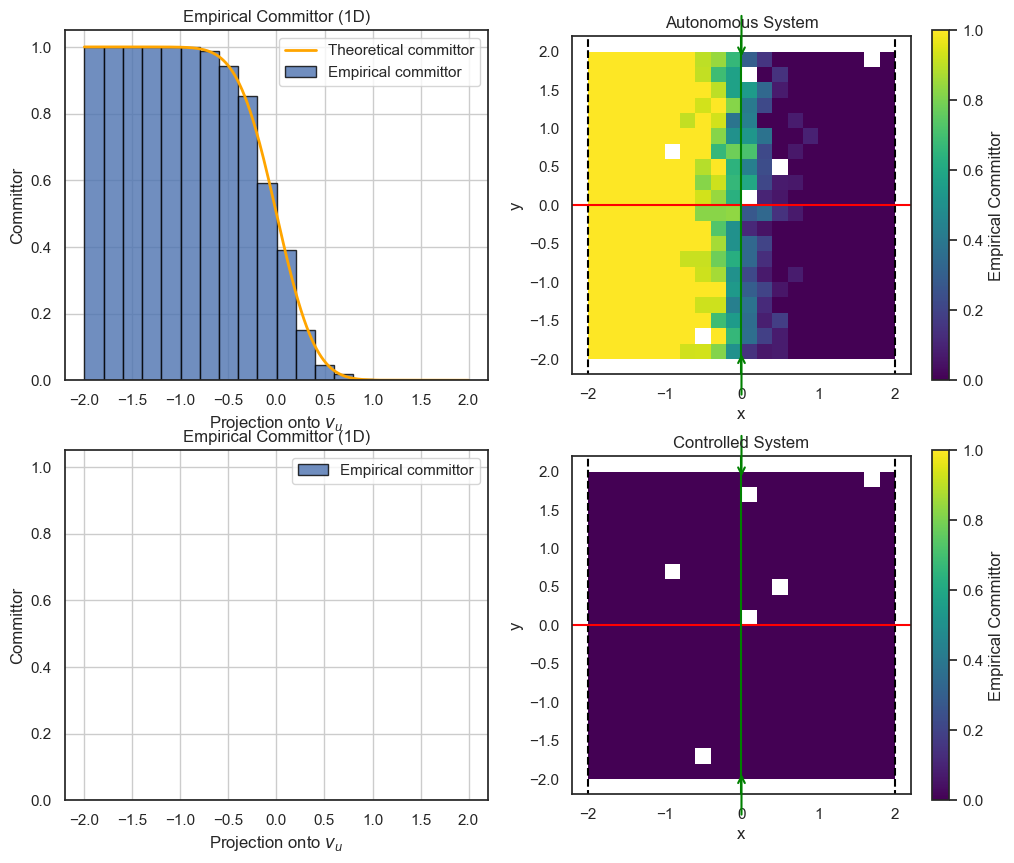

In [131]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10), sharex=False, sharey=False)
ax = ax.flatten()
plot_committor_1d_histogram(bin_centers=results_aut['bin_centers_1d'],empirical_committor=results_aut['committor_vals_1d'],true_committor=committor,true_committor_xs=-xs,ax=ax[0])
plot_committor_2d(a=a, committor_vals_2d=results_aut['committor_vals_2d'], bin_centers_2d=results_aut['bin_centers_2d'], counts_2d=results_aut['counts_2d'], ax=ax[1], title='Autonomous System', Q_mat=Q_mat, Lambda=Lambda)

plot_committor_1d_histogram(bin_centers=results_control['bin_centers_1d'], empirical_committor=results_control['committor_vals_1d'], ax=ax[2])
plot_committor_2d(a=a, committor_vals_2d=results_control['committor_vals_2d'], bin_centers_2d=results_control['bin_centers_2d'], counts_2d=results_control['counts_2d'], ax=ax[3], title='Controlled System', Q_mat=Q_mat, Lambda=Lambda)

In [132]:

# Example matrices
D_mat = D*np.array([[1.0, 0.0], [0.0, 1.0]])

# Solve A Σ + Σ Aᵀ = -D
Sigma = solve_continuous_lyapunov(A, D_mat)

print("Sigma =\n", Sigma)

# Optional: verify the solution
residual = A @ Sigma + Sigma @ A.T + D_mat
print("Residual (should be near zero):\n", residual)

Sigma =
 [[ 0.05        0.02757659]
 [ 0.02757659 -0.05      ]]
Residual (should be near zero):
 [[ 1.00000000e-01 -3.46944695e-18]
 [-3.46944695e-18  1.00000000e-01]]


C:\Users\abel_\AppData\Local\Temp\ipykernel_24080\3823963819.py:5: RuntimeWarning: Input "a" has an eigenvalue pair whose sum is very close to or exactly zero. The solution is obtained via perturbing the coefficients.
  Sigma = solve_continuous_lyapunov(A, D_mat)


In [133]:


def solve_general_lyapunov(A: np.ndarray, D: np.ndarray) -> np.ndarray:
    """
    Solve A Σ + Σ Aᵀ = -D for arbitrary A using Kronecker product.
    Works even when A has both stable and unstable eigenvalues.
    """
    n = A.shape[0]
    L = kron(np.eye(n), A) + kron(A, np.eye(n))  # (n^2, n^2)
    dvec = -D.reshape(-1)
    sigma_vec = solve(L, dvec)
    Sigma = sigma_vec.reshape(n, n)
    return Sigma


In [134]:
Sigma = solve_general_lyapunov(A, D_mat)

print("Sigma:\n", Sigma)
print("Residual (should be close to 0):\n", A @ Sigma + Sigma @ A.T + D_mat)

LinAlgError: Matrix is singular.

In [135]:

def solve_general_lyapunov_fallback(A: np.ndarray, D: np.ndarray) -> np.ndarray:
    n = A.shape[0]
    L = kron(np.eye(n), A) + kron(A, np.eye(n))
    dvec = -D.reshape(-1)
    try:
        sigma_vec = solve(L, dvec)
    except np.linalg.LinAlgError:
        print("Warning: Sylvester operator is singular. Solving least-squares instead.")
        sigma_vec, *_ = lstsq(L, dvec)
    return sigma_vec.reshape(n, n)


In [136]:
Sigma = solve_general_lyapunov_fallback(A, D_mat)
print("Sigma:\n", Sigma)
print("Residual (should be close to 0):\n", A @ Sigma + Sigma @ A.T + D_mat)

Sigma:
 [[-5.000000e-02 -3.061617e-18]
 [-3.061617e-18  5.000000e-02]]
Residual (should be close to 0):
 [[0.000000e+00 3.061617e-18]
 [3.061617e-18 0.000000e+00]]
